# Data Science & AI/ML 

## 0. Setup — libraries, folders, data generation

In [1]:
import os, json, subprocess, sys
from pathlib import Path
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'     

if Path.cwd().name == 'notebooks':
    os.chdir('..')

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy, sklearn, joblib, tensorflow as tf
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

for p in ['src', 'data/raw', 'outputs/figures', 'models', 'notebooks']:
    Path(p).mkdir(parents=True, exist_ok=True)

versions = {'python': sys.version.split()[0], 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__,
            'tensorflow': tf.__version__}
json.dump(versions, open('outputs/versions.json', 'w'), indent=2)
print(versions)

{'python': '3.13.5', 'numpy': '2.3.5', 'pandas': '2.3.2', 'scipy': '1.16.2', 'scikit-learn': '1.8.0', 'tensorflow': '2.21.0'}


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
rng = np.random.default_rng(404)
n = 300
cols = ['visits', 'recency', 'engagement', 'spend']
x = rng.normal(size=(n, 4))
group = rng.choice(["G1", "G2"], size=n)
score = x @ np.array([0.6, -0.9, 1.1, 0.4])
score += 0.4 * (group == "G2") + rng.normal(0, 1, n)
y = (score > 0).astype(int)
df = pd.DataFrame(np.round(50 + 10*x, 2), columns=cols)
df.insert(0, "record_id", np.arange(1, n+1))
df["group"] = group
df["response"] = y
for col in cols[:2]:
    df.loc[rng.choice(n, 15, replace=False), col] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/set_d.csv", index=False)


## 1. Data Audit & Partition (F1)

In [16]:
import matplotlib.pyplot as plt
df = pd.read_csv("data/raw/set_d.csv")

print(df.head())

   record_id  visits  recency  engagement  spend group  response
0          1   53.96    43.84       54.57  58.93    G2         1
1          2     NaN    49.75       52.97  63.64    G2         1
2          3   35.39    66.52       44.98  47.33    G2         0
3          4   45.01    42.80       47.62  54.48    G1         1
4          5   53.84    53.72       48.33  58.30    G2         1


In [3]:
raw = pd.read_csv('data/raw/set_d.csv')          # raw file kyarey change nathi karvani
print('Raw shape          :', raw.shape)
print('Exact duplicates   :', raw.duplicated().sum())
print('Missing values:\n', raw.isna().sum())
print('Target counts (raw):\n', raw['response'].value_counts())

df = raw.drop_duplicates().reset_index(drop=True)   # duplicates split pehla remove
print('\nClean shape        :', df.shape, '| unique record_id:', df['record_id'].nunique())
assert df['record_id'].nunique() == 300

Raw shape          : (305, 7)
Exact duplicates   : 5
Missing values:
 record_id      0
visits        16
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64
Target counts (raw):
 response
1    177
0    128
Name: count, dtype: int64

Clean shape        : (300, 7) | unique record_id: 300


In [ ]:
train_val, test = train_test_split(df, test_size=0.2, stratify=df['response'], random_state=42)
fit, val = train_test_split(train_val, test_size=0.2, stratify=train_val['response'], random_state=42)

print('fit / val / test sizes:', len(fit), len(val), len(test))

splits = pd.concat([
    pd.DataFrame({'record_id': fit['record_id'],  'partition': 'fit'}),
    pd.DataFrame({'record_id': val['record_id'],  'partition': 'validation'}),
    pd.DataFrame({'record_id': test['record_id'], 'partition': 'test'})])
splits.to_csv('outputs/splits.csv', index=False)

sf, sv, st = set(fit['record_id']), set(val['record_id']), set(test['record_id'])
assert not (sf & sv) and not (sf & st) and not (sv & st)
print('Partitions disjoint: True | total =', len(sf | sv | st))

audit = {'raw_shape': list(raw.shape), 'exact_duplicates': int(raw.duplicated().sum()),
         'missing_counts': raw.isna().sum().to_dict(),
         'target_counts_raw': raw['response'].value_counts().to_dict(),
         'clean_unique_records': int(df['record_id'].nunique()),
         'sizes': {'fit': len(fit), 'validation': len(val), 'test': len(test)}}
json.dump(audit, open('outputs/audit.json', 'w'), indent=2)

fit / val / test sizes: 192 48 60
Partitions disjoint: True | total = 300


**Interpretation:** The raw data (305 rows) had 5 exact duplicates; after removing them we have 300 unique records, and the target is slightly imbalanced (177 vs 128 in raw data).  
The fit/validation/test sets are 192/48/60 records and their IDs do not overlap, so there is no data leakage between partitions.

## Task 1. Maths & Advanced Statistics

### M1 — Descriptive statistics 

{'n': 192, 'mean': 51.00182291666667, 'median': 51.405, 'std_ddof1': 10.288960500356747}


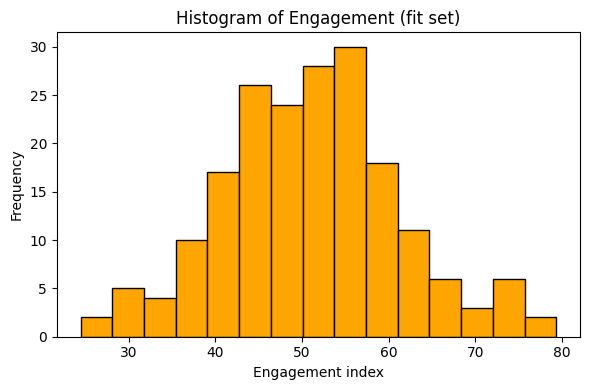

In [17]:
eng = fit['engagement'].dropna()          
m1 = {'n': int(eng.count()), 'mean': float(eng.mean()), 'median': float(eng.median()), 'std_ddof1': float(eng.std(ddof=1))}
print(m1)

plt.figure(figsize=(6, 4))
plt.hist(eng, bins=15, edgecolor='black', color='orange')
plt.title('Histogram of Engagement (fit set)')
plt.xlabel('Engagement index'); plt.ylabel('Frequency')
plt.tight_layout(); plt.savefig('outputs/figures/engagement_hist.png', dpi=150); plt.show()

**Interpretation:** On 192 observed values, mean ≈ 51.00, median ≈ 51.41 and standard deviation ≈ 10.29; the mean and median are very close.  
The histogram is roughly bell-shaped, so engagement looks approximately normally distributed.

### M2 —  Statistical Inference

**H0:** mean engagement of G1 = mean engagement of G2  
**H1:** mean engagement of G1 ≠ mean engagement of G2  (two-sided, α = 0.05)

In [6]:
g1 = fit.loc[fit['group'] == 'G1', 'engagement'].dropna()
g2 = fit.loc[fit['group'] == 'G2', 'engagement'].dropna()
t_stat, p_val = stats.ttest_ind(g1, g2, equal_var=False)       # Welch test
print(f'n(G1)={len(g1)}, n(G2)={len(g2)} | t = {t_stat:.4f} | p = {p_val:.4f}')

ci_low, ci_high = stats.t.interval(0.95, df=len(eng) - 1, loc=eng.mean(), scale=stats.sem(eng))
print(f'95% CI for overall mean engagement: ({ci_low:.3f}, {ci_high:.3f})')

inference = {'n_G1': len(g1), 'n_G2': len(g2), 't_stat': float(t_stat), 'p_value': float(p_val),
             'ci95_low': float(ci_low), 'ci95_high': float(ci_high)}
json.dump({'descriptive': m1, 'inference': inference}, open('outputs/stats_summary.json', 'w'), indent=2)

n(G1)=84, n(G2)=108 | t = 0.7230 | p = 0.4707
95% CI for overall mean engagement: (49.537, 52.466)


**Interpretation:** Welch t-test (G1 n=84, G2 n=108): t = 0.723, p = 0.471 > 0.05, so we fail to reject H0 — there is no evidence of a difference in mean engagement between G1 and G2. The 95% CI for the overall mean is (49.54, 52.47): if we repeated the sampling many times, about 95% of such intervals would contain the true mean; this assumes independent records and approximate normality (large n helps via the CLT), and it does not imply causation.

### M3 — Linear algebra

In [ ]:
sub = fit[['engagement', 'visits']].dropna()     
X = sub.values
n = len(X)
Xc = X - X.mean(axis=0)                   
cov = Xc.T @ Xc / (n - 1)                      
print('n =', n); print('Covariance matrix:\n', cov)

vals, vecs = np.linalg.eigh(cov)                 
share = float(vals.max() / vals.sum())
print('Eigenvalues:', vals)
print('Largest eigenvalue / sum =', round(share, 4))
print('Principal direction (PC1):', vecs[:, -1])

json.dump({'n': n, 'cov': cov.tolist(), 'eigenvalues': vals.tolist(), 'pc1_share': share,
           'pc1_direction': vecs[:, -1].tolist()}, open('outputs/linear_algebra.json', 'w'), indent=2)

n = 181
Covariance matrix:
 [[103.65708913   4.11811311]
 [  4.11811311 103.06117496]]
Eigenvalues: [ 99.23025399 107.4880101 ]
Largest eigenvalue / sum = 0.52
Principal direction (PC1): [-0.73217627 -0.6811152 ]


**Interpretation:** The largest eigenvalue divided by the sum is 0.52, so PC1 explains only about 52% of the variance (the covariance is small, ≈ 4.1, so engagement and visits are nearly uncorrelated).  
PC1 direction ≈ [-0.73, -0.68] (the sign is arbitrary): both variables load in the same direction, but the pattern is weak.

## Task 2. Preprocessing & Feature Engineering 

Rules: imputer / encoder / scaler **sirf fit (192)** par fit thase. Validation ane test ma sirf `transform`.  
`engineered_feature = engagement / (recency + 1)` → imputation pachi, scaling pehla (original scale).

In [ ]:
num_cols = ['visits', 'recency', 'engagement', 'spend']

imputer = SimpleImputer(strategy='median').fit(fit[num_cols])
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(fit[['group']])

def numeric_part(d):
    num = pd.DataFrame(imputer.transform(d[num_cols]), columns=num_cols, index=d.index)
    num['engineered_feature'] = num['engagement'] / (num['recency'] + 1)
    return num

scaler = StandardScaler().fit(numeric_part(fit))    

def transform(d):
    scaled = scaler.transform(numeric_part(d))       
    onehot = ohe.transform(d[['group']])           
    return np.hstack([scaled, onehot])

feature_names = num_cols + ['engineered_feature'] + list(ohe.get_feature_names_out(['group']))
X_fit, X_val, X_test = transform(fit), transform(val), transform(test)
y_fit, y_val, y_test = fit['response'].values, val['response'].values, test['response'].values

print('Shapes:', X_fit.shape, X_val.shape, X_test.shape)
print('Features:', feature_names)
print('All finite:', all(np.isfinite(a).all() for a in (X_fit, X_val, X_test)))

joblib.dump({'imputer': imputer, 'encoder': ohe, 'scaler': scaler, 'feature_names': feature_names},
            'models/preprocessing.joblib')
pd.DataFrame({'step': ['imputer', 'encoder', 'scaler'],
              'fitted_on': 'fit partition (192 rows)',
              'detail': ['median of 4 numeric cols', 'one-hot group, handle_unknown=ignore',
                         'StandardScaler on 5 numeric cols']}).to_csv('outputs/preprocessing_audit.csv', index=False)

Shapes: (192, 7) (48, 7) (60, 7)
Features: ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']
All finite: True


**Interpretation:** The transformed shapes are (192, 7), (48, 7) and (60, 7) with 7 features, and all values are finite; the imputer, encoder and scaler were fitted on the fit set only.  
The target (it would leak the answer), record_id (just a label with no meaning) and test statistics (they would leak holdout information) were kept out of training.

## Task 3. Supervised Learning 

**Target:** `response` | **Predictors:** 7 transformed features (visits, recency, engagement, spend, engineered_feature, group_G1, group_G2)  
**Models:** DummyClassifier(most_frequent) & LogisticRegression(max_iter=1000) | **Threshold:** 0.5 | undefined precision/recall → `zero_division=0`

                     accuracy  precision  recall     f1
Baseline (Dummy)        0.583      0.583   1.000  0.737
Logistic Regression     0.817      0.833   0.857  0.845


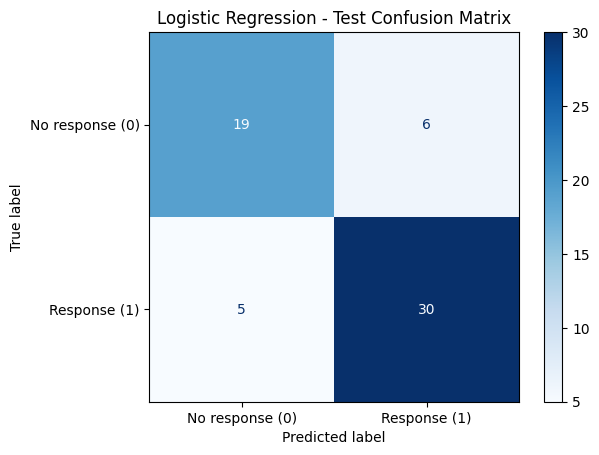

TN, FP, FN, TP = [19  6  5 30]


In [ ]:
def get_metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            'recall': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            'f1': f1_score(y_true, y_pred, pos_label=1, zero_division=0)}

dummy = DummyClassifier(strategy='most_frequent').fit(X_fit, y_fit)
logreg = LogisticRegression(max_iter=1000, random_state=42).fit(X_fit, y_fit)

dummy_pred = dummy.predict(X_test)
log_prob = logreg.predict_proba(X_test)[:, 1]
log_pred = (log_prob >= 0.5).astype(int)

results = pd.DataFrame({'Baseline (Dummy)': get_metrics(y_test, dummy_pred),
                        'Logistic Regression': get_metrics(y_test, log_pred)}).T
print(results.round(3))

cm = confusion_matrix(y_test, log_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['No response (0)', 'Response (1)']).plot(cmap='Blues')
plt.title('Logistic Regression - Test Confusion Matrix')
plt.savefig('outputs/figures/confusion_logistic.png', dpi=150, bbox_inches='tight'); plt.show()
print('TN, FP, FN, TP =', cm.ravel())

pd.DataFrame({'record_id': test['record_id'].values, 'true_label': y_test,
              'predicted_label': log_pred, 'prob_class1': log_prob}
             ).to_csv('outputs/logistic_predictions.csv', index=False)

**Interpretation:** The baseline accuracy is 0.583, while Logistic Regression gets accuracy 0.817, precision 0.833, recall 0.857 and F1 0.845 — a clear improvement (about +23 points accuracy; F1 0.737 → 0.845).  
A false positive (6 cases) means wasted campaign cost, while a false negative (5 cases) means a likely responder is missed and revenue is lost; with only 60 test records there is uncertainty, so this is not proof of deployment readiness.

## Task 4. Unsupervised Learning — K-Means 

Features: 5 scaled numeric fit features (4 numeric + engineered_feature). Group one-hot, target ane ID **nathi** vaparya.

   k   inertia  silhouette
0  2  713.0304      0.2259
1  3  613.5511      0.1872
2  4  541.6453      0.1907
Chosen k = 2
         visits  recency  engagement  spend  engineered_feature  size
cluster                                                              
0         49.37    55.25       46.09  50.18                0.83   109
1         49.54    44.17       57.45  50.97                1.29    83


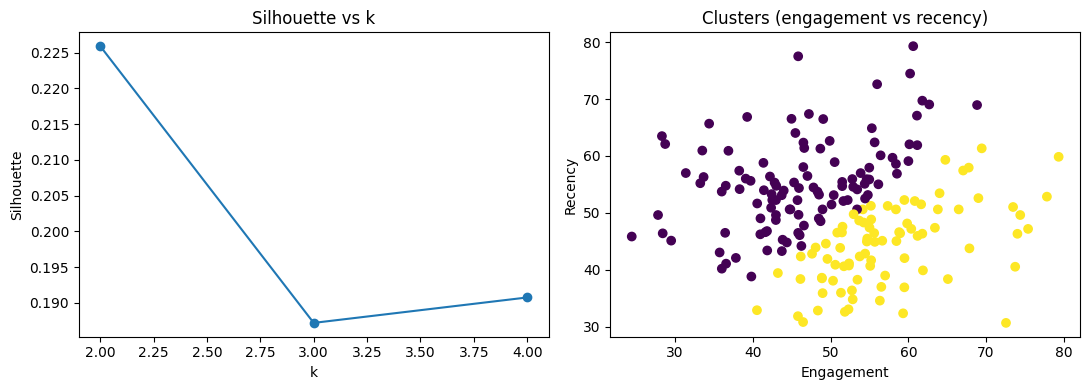

In [18]:
X_clu = X_fit[:, :5]
rows = []
for k in [2, 3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_clu)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X_clu, km.labels_)})
k_scores = pd.DataFrame(rows)
k_scores.to_csv('outputs/kmeans_scores.csv', index=False)
print(k_scores.round(4))

best_k = int(k_scores.loc[k_scores['silhouette'].idxmax(), 'k'])   # tie hoy to nanu k (pehlu row)
print('Chosen k =', best_k)

final_km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X_clu)
profile_df = numeric_part(fit).copy()               # original-scale values
profile_df['cluster'] = final_km.labels_
profile = profile_df.groupby('cluster').agg(['mean']).round(2)
profile.columns = [c[0] for c in profile.columns]
profile['size'] = profile_df.groupby('cluster').size()
profile.to_csv('outputs/cluster_profiles.csv')
print(profile)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_scores['k'], k_scores['silhouette'], marker='o'); ax[0].set_title('Silhouette vs k')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Silhouette')
sc = ax[1].scatter(profile_df['engagement'], profile_df['recency'], c=profile_df['cluster'], cmap='viridis')
ax[1].set_title('Clusters (engagement vs recency)'); ax[1].set_xlabel('Engagement'); ax[1].set_ylabel('Recency')
plt.tight_layout(); plt.savefig('outputs/figures/kmeans_diagnostics.png', dpi=150); plt.show()

**Interpretation:** k=2 has the highest silhouette (0.226), so it was chosen; a silhouette below 0.25 means the clusters are weak and overlapping.  
**Cluster 0 = "Cool / Low-Engagement" (engagement 46, recency 55)** → action: send a re-engagement offer; **Cluster 1 = "Active / High-Engagement" (engagement 57, recency 44)** → action: run a loyalty or upsell offer. Cluster IDs are arbitrary labels (0/1 have no meaning) and do not correspond to the target classes (response 0/1).

## TAsk 5. Deep Learning — ANN 

In [19]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)      

model = keras.Sequential([
    layers.Input(shape=(X_fit.shape[1],)),   
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy', metrics=['accuracy'])
model.summary()
print('Trainable parameters:', model.count_params())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 273


**Interpretation:** The architecture is 7 → 16 → 8 → 1 with 273 trainable parameters in total (128 + 136 + 9).  
The sigmoid output gives a probability between 0 and 1, and binary cross-entropy is the correct loss for a 0/1 target; Adam (lr = 0.001) is a stable optimizer choice.

Seed = 42 | Epochs run = 50 | Best epoch = 50
Final train loss = 0.3931 | Final val loss = 0.3144


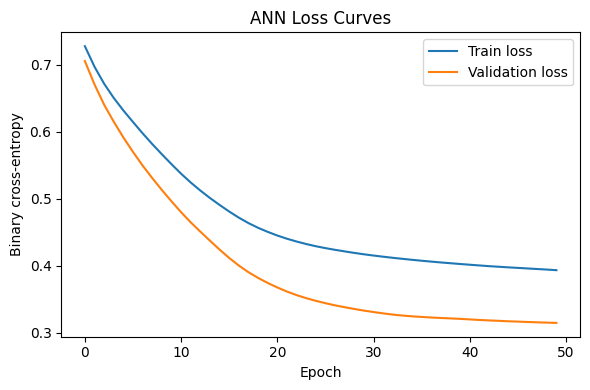

In [12]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(X_fit, y_fit, validation_data=(X_val, y_val),
                    batch_size=16, epochs=50, callbacks=[early_stop], verbose=0)

actual_epochs = len(history.history['loss'])
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print('Seed = 42 | Epochs run =', actual_epochs, '| Best epoch =', best_epoch)
print('Final train loss =', round(history.history['loss'][-1], 4), '| Final val loss =', round(history.history['val_loss'][-1], 4))

plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('ANN Loss Curves'); plt.xlabel('Epoch'); plt.ylabel('Binary cross-entropy'); plt.legend()
plt.tight_layout(); plt.savefig('outputs/figures/ann_loss_curves.png', dpi=150); plt.show()

**Interpretation:** Training ran for all 50 epochs and the best epoch was also 50, so validation loss kept improving until the end (early stopping did not trigger).  
Train and validation loss are close (validation is even slightly lower), so there is no overfitting; the model may be slightly underfitted / not fully converged and could improve with more epochs.

                     accuracy  precision  recall     f1
Baseline (Dummy)        0.583      0.583   1.000  0.737
Logistic Regression     0.817      0.833   0.857  0.845
ANN                     0.833      0.838   0.886  0.861


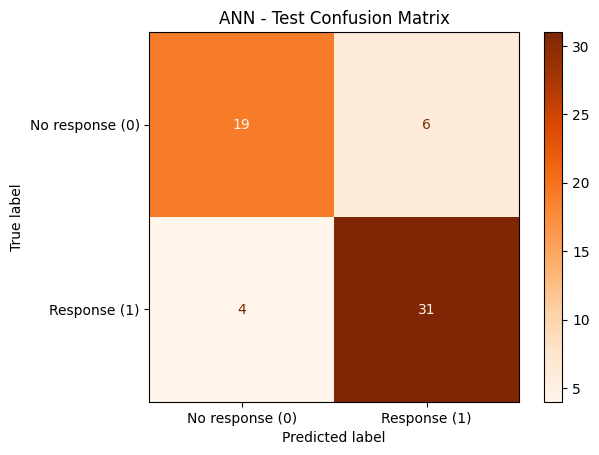

In [13]:
ann_prob = model.predict(X_test, verbose=0).ravel()
ann_pred = (ann_prob >= 0.5).astype(int)

ann_pred_df = pd.DataFrame({'record_id': test['record_id'].values, 'true_label': y_test,
                            'predicted_label': ann_pred, 'prob_class1': ann_prob})
ann_pred_df.to_csv('models/ann_predictions.csv', index=False)
model.save('models/ann_model.keras')
model.save_weights('models/ann.weights.h5')

comparison = pd.DataFrame({'Baseline (Dummy)': get_metrics(y_test, dummy_pred),
                           'Logistic Regression': get_metrics(y_test, log_pred),
                           'ANN': get_metrics(y_test, ann_pred)}).T
comparison.to_csv('outputs/model_comparison.csv')
print(comparison.round(3))

cm_ann = confusion_matrix(y_test, ann_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm_ann, display_labels=['No response (0)', 'Response (1)']).plot(cmap='Oranges')
plt.title('ANN - Test Confusion Matrix')
plt.savefig('outputs/figures/confusion_ann.png', dpi=150, bbox_inches='tight'); plt.show()

**Interpretation:** ANN: accuracy 0.833, F1 0.861 vs Logistic Regression F1 0.845 — the difference is only 0.016 (about 1 record), which is within noise on 60 test records.  
Model preference: **Logistic Regression** (simpler, easier to explain, similar performance); the ANN is not clearly better.

In [ ]:
lp = pd.read_csv('outputs/logistic_predictions.csv')
ap = pd.read_csv('models/ann_predictions.csv')
assert (lp['record_id'].values == ap['record_id'].values).all()          # same test IDs
assert set(lp['record_id']) == set(splits.loc[splits.partition == 'test', 'record_id'])
assert np.isclose(get_metrics(lp['true_label'], lp['predicted_label'])['f1'], comparison.loc['Logistic Regression', 'f1'])
assert np.isclose(get_metrics(ap['true_label'], ap['predicted_label'])['f1'], comparison.loc['ANN', 'f1'])
print('Reconciliation OK: same 60 test IDs, metrics match saved predictions.')

loaded_model = keras.models.load_model('models/ann_model.keras')
loaded_prep = joblib.load('models/preprocessing.joblib')
print('Reload OK | features:', loaded_prep['feature_names'])

Reconciliation OK: same 60 test IDs, metrics match saved predictions.
Reload OK | features: ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']


## Final Notes
- Badho data synthetic che; result ne causal ke deployment-ready na gano.
- Test set par kyarey tuning nathi thayu; seed 42 fix che.
- Chhoti 60-record holdout hovathi metrics ma uncertainty vadhare hoy.